# Arrhythmia classification

Dataset: Cardiac Arrhythmia Database from the UCI Machine Learning Repository (452 patients, 279 attributes + 1 class label).

What we do in this notebook:
1. Load and explore the data
2. Handle missing values
3. Train/test split and scaling
4. Train six classification models
5. Evaluate them (and check overfitting)
6. Apply PCA
7. Train the models again on the PCA features
8. Compare before vs after PCA
9. Conclusions

The main question is whether PCA helps, by reducing the number of features.

## 1. Load and explore the data

`arrhythmia.data` has no header row, so the column names are built from the dataset documentation (`arrhythmia.names` on the UCI page):

- the first 15 attributes are general patient measurements (age, sex, height, weight, QRS duration, intervals, angles, heart rate)
- the next 144 are waveform width/shape features (12 features for each of the 12 ECG channels: DI, DII, DIII, AVR, AVL, AVF, V1-V6)
- the next 120 are waveform amplitude features (10 for each channel)
- the last column is the target `Class` (1-16): 1 is a normal ECG, 2-15 are different arrhythmia types and 16 is "other"

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# column names, taken from the UCI documentation
base_names = ['Age', 'Sex', 'Height', 'Weight', 'QRS_duration', 'PR_interval', 'QT_interval',
              'T_interval', 'P_interval', 'QRS_angle', 'T_angle', 'P_angle', 'QRST_angle',
              'J_angle', 'Heart_rate']

channels = ['DI', 'DII', 'DIII', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

width_features = ['Qwave_width', 'Rwave_width', 'Swave_width', 'Rprime_width', 'Sprime_width',
                   'num_intrinsic_deflections', 'ragged_R', 'diphasic_R', 'ragged_P',
                   'diphasic_P', 'ragged_T', 'diphasic_T']

amp_features = ['JJ_amp', 'Q_amp', 'R_amp', 'S_amp', 'Rprime_amp', 'Sprime_amp',
                 'P_amp', 'T_amp', 'QRSA', 'QRSTA']

col_names = list(base_names)
for ch in channels:
    col_names += [f'{ch}_{f}' for f in width_features]
for ch in channels:
    col_names += [f'{ch}_{f}' for f in amp_features]
col_names.append('Class')

print(f"Number of column names built: {len(col_names)}  (expected 280 = 279 features + 1 target)")

df = pd.read_csv('arrhythmia.data', header=None, names=col_names)
print("Dataset shape:", df.shape)


Number of column names built: 280  (expected 280 = 279 features + 1 target)
Dataset shape: (452, 280)


In [2]:

# First and last few rows
df.head()


,Age,Sex,Height,Weight,QRS_duration,PR_interval,QT_interval,T_interval,P_interval,QRS_angle,T_angle,P_angle,QRST_angle,J_angle,Heart_rate,...,V5_P_amp,V5_T_amp,V5_QRSA,V5_QRSTA,V6_JJ_amp,V6_Q_amp,V6_R_amp,V6_S_amp,V6_Rprime_amp,V6_Sprime_amp,V6_P_amp,V6_T_amp,V6_QRSA,V6_QRSTA,Class
0,75,0,190,80,91,193,371,174,121,-16,13,64,-2,?,63,...,0.9,3.9,25.5,62.9,-0.3,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,37,-17,31,?,53,...,0.4,2.6,21.6,43.4,-0.5,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,34,70,66,23,75,...,0.4,3.4,11.5,48.2,0.9,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,11,-5,20,?,71,...,0.6,3.0,36.8,68.0,0.1,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,13,61,3,?,?,...,-0.2,2.9,21.7,48.9,-0.4,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


In [3]:

df.tail()


,Age,Sex,Height,Weight,QRS_duration,PR_interval,QT_interval,T_interval,P_interval,QRS_angle,T_angle,P_angle,QRST_angle,J_angle,Heart_rate,...,V5_P_amp,V5_T_amp,V5_QRSA,V5_QRSTA,V6_JJ_amp,V6_Q_amp,V6_R_amp,V6_S_amp,V6_Rprime_amp,V6_Sprime_amp,V6_P_amp,V6_T_amp,V6_QRSA,V6_QRSTA,Class
447,53,1,160,70,80,199,382,154,117,-37,4,40,-27,?,63,...,0.8,1.0,-8.4,-0.6,0.0,0.0,4.3,-5.0,0.0,0.0,0.7,0.6,-4.4,-0.5,1
448,37,0,190,85,100,137,361,201,73,86,66,52,79,?,73,...,0.4,3.7,50.7,82.5,-0.5,0.0,15.6,-1.6,0.0,0.0,0.4,2.4,38.0,62.4,10
449,36,0,166,68,108,176,365,194,116,-85,-19,-61,-70,84,84,...,1.9,-2.5,-39.6,-63.6,1.2,0.0,16.3,-28.6,0.0,0.0,1.5,1.0,-44.2,-33.2,2
450,32,1,155,55,93,106,386,218,63,54,29,-22,43,103,80,...,0.4,3.2,29.7,61.0,0.2,-0.4,12.0,-0.7,0.0,0.0,0.5,2.4,25.0,46.6,1
451,78,1,160,70,79,127,364,138,78,28,79,52,47,?,75,...,0.6,1.7,26.7,38.9,-0.3,0.0,10.4,-1.8,0.0,0.0,0.5,1.6,21.3,32.8,1


In [4]:

print("Dimensions (rows, columns):", df.shape)


Dimensions (rows, columns): (452, 280)


In [5]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Columns: 280 entries, Age to Class
dtypes: float64(120), int64(155), str(5)
memory usage: 988.9 KB


In [6]:

# some columns are still object dtype here because of the '?' markers
df.describe(include='all').T.head(20)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,452.0,NaN,NaN,NaN,46.471239,16.466631,0.0,36.0,47.0,58.0,83.0
Sex,452.0,NaN,NaN,NaN,0.550885,0.497955,0.0,0.0,1.0,1.0,1.0
Height,452.0,NaN,NaN,NaN,166.188053,37.17034,105.0,160.0,164.0,170.0,780.0
Weight,452.0,NaN,NaN,NaN,68.170354,16.590803,6.0,59.0,68.0,79.0,176.0
QRS_duration,452.0,NaN,NaN,NaN,88.920354,15.364394,55.0,80.0,86.0,94.0,188.0
PR_interval,452.0,NaN,NaN,NaN,155.152655,44.842283,0.0,142.0,157.0,175.0,524.0
QT_interval,452.0,NaN,NaN,NaN,367.207965,33.385421,232.0,350.0,367.0,384.0,509.0
T_interval,452.0,NaN,NaN,NaN,169.949115,35.633072,108.0,148.0,162.0,179.0,381.0
P_interval,452.0,NaN,NaN,NaN,90.004425,25.826643,0.0,79.0,91.0,102.0,205.0
QRS_angle,452.0,NaN,NaN,NaN,33.676991,45.431434,-172.0,3.75,40.0,66.0,169.0


The target is the last column, `Class`. Let's look at how it is distributed.

Class
1     245
2      44
3      15
4      15
5      13
6      25
7       3
8       2
9       9
10     50
14      4
15      5
16     22
Name: count, dtype: int64


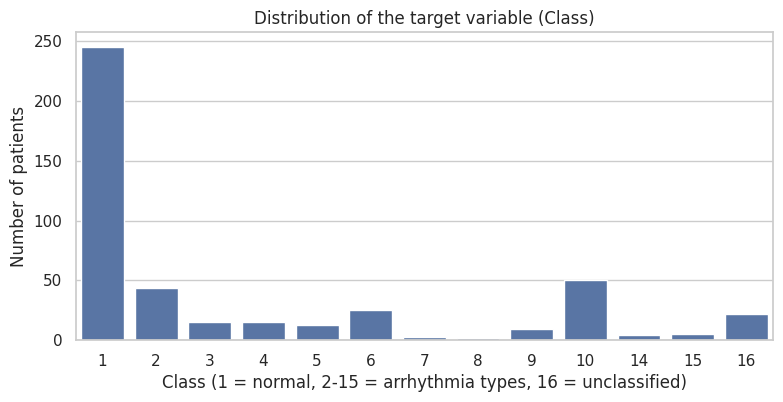


Number of distinct classes present in the data: 13
Fraction of patients labeled 'normal' (class 1): 54.2%


In [7]:

class_counts = df['Class'].value_counts().sort_index()
print(class_counts)

plt.figure(figsize=(9, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color='#4C72B0')
plt.xlabel('Class (1 = normal, 2-15 = arrhythmia types, 16 = unclassified)')
plt.ylabel('Number of patients')
plt.title('Distribution of the target variable (Class)')
plt.show()

print(f"\nNumber of distinct classes present in the data: {df['Class'].nunique()}")
print(f"Fraction of patients labeled 'normal' (class 1): {(df['Class'] == 1).mean():.1%}")


This is a multi-class problem and the classes are very imbalanced. About 54% of the patients are class 1 (normal), while classes 7, 8, 14 and 15 have 5 patients or fewer each. Because of this, accuracy alone can be misleading, so weighted recall and precision are reported too.

## 2. Data preprocessing

### 2.1 Missing values
According to the UCI documentation, missing values are written as `?`. They are replaced with `NaN` and every column is converted to numeric so pandas and scikit-learn can work with them.

In [8]:

# '?' means missing, so turn it into NaN and make all feature columns numeric
df_clean = df.replace('?', np.nan)
feature_cols = [c for c in df_clean.columns if c != 'Class']
df_clean[feature_cols] = df_clean[feature_cols].apply(pd.to_numeric, errors='coerce')
df_clean['Class'] = df_clean['Class'].astype(int)

total_missing = df_clean.isna().sum().sum()
print(f"Total missing values in the dataset: {total_missing}")
print(f"Number of columns with at least one missing value: {(df_clean.isna().sum() > 0).sum()}")


Total missing values in the dataset: 408
Number of columns with at least one missing value: 5


### 2.2 Where the missing values are
Checking which columns are affected, to decide between dropping and imputing.

J_angle       83.185841
P_angle        4.867257
T_angle        1.769912
Heart_rate     0.221239
QRST_angle     0.221239
dtype: float64


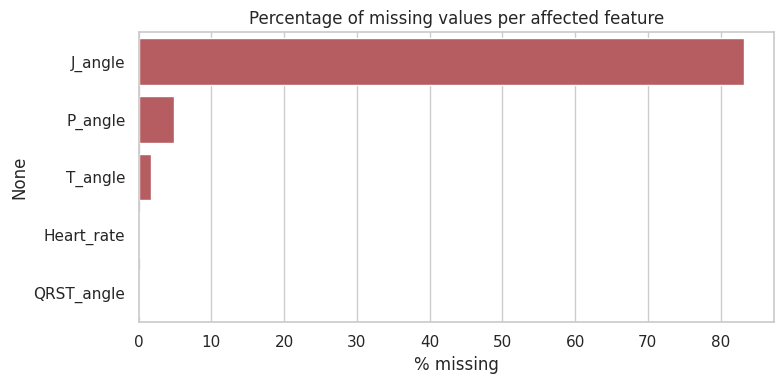

In [9]:

missing_pct = (df_clean.isna().sum() / len(df_clean) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(missing_pct)

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color='#C44E52')
plt.xlabel('% missing')
plt.title('Percentage of missing values per affected feature')
plt.tight_layout()
plt.show()


- `J_angle` is missing in about 83% of the rows. Imputing that would mean inventing most of the column, so it is dropped.
- `P_angle` (4.9%), `T_angle` (1.8%), `QRST_angle` and `Heart_rate` (0.2% each) have very few missing values, so they are kept and imputed.
- The cut-off for dropping a column is 50% missing.

In [10]:

MISSING_THRESHOLD = 0.50  # drop any column missing in more than 50% of rows

cols_to_drop = df_clean.columns[df_clean.isna().mean() > MISSING_THRESHOLD].tolist()
print("Columns dropped for excessive missingness:", cols_to_drop)

df_clean = df_clean.drop(columns=cols_to_drop)
print("Shape after dropping high-missingness columns:", df_clean.shape)


Columns dropped for excessive missingness: ['J_angle']
Shape after dropping high-missingness columns: (452, 279)


### 2.3 Imputing the rest
Median imputation is used for the four remaining columns. The median is less affected by outliers than the mean, and these measurements are skewed.

In [11]:

from sklearn.impute import SimpleImputer

remaining_missing_cols = df_clean.columns[df_clean.isna().any()].tolist()
print("Columns still needing imputation:", remaining_missing_cols)

imputer = SimpleImputer(strategy='median')
df_clean[remaining_missing_cols] = imputer.fit_transform(df_clean[remaining_missing_cols])

print("\nRemaining missing values after imputation:", df_clean.isna().sum().sum())
print("Final dataset shape:", df_clean.shape)


Columns still needing imputation: ['T_angle', 'P_angle', 'QRST_angle', 'Heart_rate']

Remaining missing values after imputation: 0
Final dataset shape: (452, 279)


### 2.4 Final checks
Columns that never change (zero variance) are dropped, since they carry no information and can cause problems when scaling. Then we check that everything is numeric and no missing values are left.

In [12]:

# drop columns that never change
constant_cols = [c for c in df_clean.columns if c != 'Class' and df_clean[c].nunique() <= 1]
print(f"Constant columns dropped: {len(constant_cols)}")
df_clean = df_clean.drop(columns=constant_cols)

assert df_clean.isna().sum().sum() == 0, "There are still missing values!"
assert all(df_clean.dtypes != object), "There are still non-numeric columns!"

print("Dataset is fully numeric with no missing values.")
print("Final shape ready for modeling:", df_clean.shape)
df_clean.head()


Constant columns dropped: 17
Dataset is fully numeric with no missing values.
Final shape ready for modeling: (452, 262)


,Age,Sex,Height,Weight,QRS_duration,PR_interval,QT_interval,T_interval,P_interval,QRS_angle,T_angle,P_angle,QRST_angle,Heart_rate,DI_Qwave_width,...,V5_Rprime_amp,V5_P_amp,V5_T_amp,V5_QRSA,V5_QRSTA,V6_JJ_amp,V6_Q_amp,V6_R_amp,V6_S_amp,V6_Rprime_amp,V6_P_amp,V6_T_amp,V6_QRSA,V6_QRSTA,Class
0,75,0,190,80,91,193,371,174,121,-16,13.0,64.0,-2.0,63.0,0,...,0.0,0.9,3.9,25.5,62.9,-0.3,0.0,9.0,-0.9,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,37.0,-17.0,31.0,53.0,0,...,0.0,0.4,2.6,21.6,43.4,-0.5,0.0,8.5,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,34.0,70.0,66.0,75.0,0,...,0.0,0.4,3.4,11.5,48.2,0.9,0.0,9.5,-2.4,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,11.0,-5.0,20.0,71.0,0,...,0.0,0.6,3.0,36.8,68.0,0.1,0.0,12.2,-2.2,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,13.0,61.0,3.0,72.0,0,...,0.0,-0.2,2.9,21.7,48.9,-0.4,0.0,13.1,-3.6,0.0,-0.1,3.9,25.4,62.8,7


## 3. Prepare the data

Split into train and test (75% / 25%) and scale the features. The scaler is fitted on the training set only and then applied to both sets, so the test set does not leak into the scaling.

The split is stratified because some classes have only 2 or 3 patients, and this keeps every class in both sets.

In [13]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

# fit the scaler on the training data only, then apply it to both sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("\nTraining class distribution:\n", y_train.value_counts().sort_index())


Training set shape: (339, 261)
Test set shape: (113, 261)

Training class distribution:
 Class
1     184
2      33
3      11
4      11
5      10
6      19
7       2
8       1
9       7
10     38
14      3
15      4
16     16
Name: count, dtype: int64


## 4. Train the models

Six models are compared:

1. KNN
2. Logistic Regression
3. Decision Tree
4. Linear SVM
5. Kernel SVM (RBF)
6. Random Forest

The helper function trains a model and returns train/test accuracy, weighted recall and precision, the confusion matrix and the classification report. The same function is used again after PCA so both runs are compared the same way.

In [14]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                              confusion_matrix, classification_report)

def get_models():
    '''new untrained models every time, so the PCA run starts clean'''
    return {
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'Logistic Regression': LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Linear SVM': SVC(kernel='linear', random_state=RANDOM_STATE),
        'Kernel SVM': SVC(kernel='rbf', random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    }

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, verbose=True):
    '''fit the model and return train/test metrics'''
    model.fit(X_tr, y_tr)
    y_pred_train = model.predict(X_tr)
    y_pred_test = model.predict(X_te)

    metrics = {
        'Model': name,
        'Train Accuracy': accuracy_score(y_tr, y_pred_train),
        'Test Accuracy': accuracy_score(y_te, y_pred_test),
        'Train Recall (weighted)': recall_score(y_tr, y_pred_train, average='weighted', zero_division=0),
        'Test Recall (weighted)': recall_score(y_te, y_pred_test, average='weighted', zero_division=0),
        'Test Precision (weighted)': precision_score(y_te, y_pred_test, average='weighted', zero_division=0),
    }

    if verbose:
        print(f"===== {name} =====")
        print(f"Train accuracy: {metrics['Train Accuracy']:.3f} | Test accuracy: {metrics['Test Accuracy']:.3f}")
        print(f"Train recall (weighted): {metrics['Train Recall (weighted)']:.3f} | "
              f"Test recall (weighted): {metrics['Test Recall (weighted)']:.3f}")
        print(f"Test precision (weighted): {metrics['Test Precision (weighted)']:.3f}")
        print("\nConfusion matrix (test set):")
        print(confusion_matrix(y_te, y_pred_test))
        print("\nClassification report (test set):")
        print(classification_report(y_te, y_pred_test, zero_division=0))
        print()

    return metrics, y_pred_test


In [15]:

results_before_pca = []
models_before = get_models()

for name, model in models_before.items():
    metrics, _ = evaluate_model(name, model, X_train_scaled, y_train, X_test_scaled, y_test)
    results_before_pca.append(metrics)

results_before_df = pd.DataFrame(results_before_pca)
results_before_df


===== KNN =====
Train accuracy: 0.619 | Test accuracy: 0.566
Train recall (weighted): 0.619 | Test recall (weighted): 0.566
Test precision (weighted): 0.465

Confusion matrix (test set):
[[60  1  0  0  0  0  0  0  0  0  0  0  0]
 [11  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  0  2  0  0  0  0  0  0  0  0  0  0]
 [ 4  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  1  0  0  0  0]
 [11  0  0  0  0  0  0  0  0  1  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  1  0  0  0  0  0  0  0  0  0  0  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.57      0.98      0.72        61
           2       0.00      0.00      0.00        11
           3       1.00      0.50      0.67         4
           4  

===== Logistic Regression =====
Train accuracy: 1.000 | Test accuracy: 0.637
Train recall (weighted): 1.000 | Test recall (weighted): 0.637
Test precision (weighted): 0.595

Confusion matrix (test set):
[[53  1  0  0  0  2  0  0  0  3  0  0  2]
 [ 5  6  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  4  0  0  0  0  0  0  0  0  0  0]
 [ 2  0  0  1  1  0  0  0  0  0  0  0  0]
 [ 2  0  0  0  0  0  0  0  0  0  0  0  1]
 [ 4  1  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  0  0  0  0  0  0  1  0  0  0  0]
 [ 5  1  0  0  0  0  0  0  0  6  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  1]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  1  0  0  0  1  0  0  0  0  0  1  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.70      0.87      0.77        61
           2       0.55      0.55      0.55        11
           3       0.80      1.00      0.89         

===== Kernel SVM =====
Train accuracy: 0.811 | Test accuracy: 0.584
Train recall (weighted): 0.811 | Test recall (weighted): 0.584
Test precision (weighted): 0.514

Confusion matrix (test set):
[[61  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 9  2  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  0  2  0  0  0  0  0  0  0  0  0  0]
 [ 4  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 6  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  0  0  0  0  0  0  0  0  0  0  0  0]
 [10  1  0  0  0  0  0  0  0  1  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 6  0  0  0  0  0  0  0  0  0  0  0  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.57      1.00      0.73        61
           2       0.67      0.18      0.29        11
           3       1.00      0.50      0.67         4
       

===== Random Forest =====
Train accuracy: 1.000 | Test accuracy: 0.743
Train recall (weighted): 1.000 | Test recall (weighted): 0.743
Test precision (weighted): 0.683

Confusion matrix (test set):
[[61  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  6  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  4  0  0  0  0  0  0  0  0  0  0]
 [ 2  1  0  1  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  3  0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  2  0  0  0  0]
 [ 5  0  0  0  0  0  0  0  0  7  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0  0  0  0]
 [ 4  1  0  0  0  0  0  0  0  1  0  0  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.72      1.00      0.84        61
           2       0.75      0.55      0.63        11
           3       0.67      1.00      0.80         4
    

,Model,Train Accuracy,Test Accuracy,Train Recall (weighted),Test Recall (weighted),Test Precision (weighted)
0,KNN,0.619469,0.566372,0.619469,0.566372,0.464852
1,Logistic Regression,1.000000,0.637168,1.000000,0.637168,0.595040
2,Decision Tree,1.000000,0.690265,1.000000,0.690265,0.645234
3,Linear SVM,1.000000,0.646018,1.000000,0.646018,0.628188
4,Kernel SVM,0.811209,0.584071,0.811209,0.584071,0.514239
5,Random Forest,1.000000,0.743363,1.000000,0.743363,0.683125


## 5. Evaluation before PCA

Confusion matrices for two of the models, then the train vs test accuracy of all of them to check for overfitting.

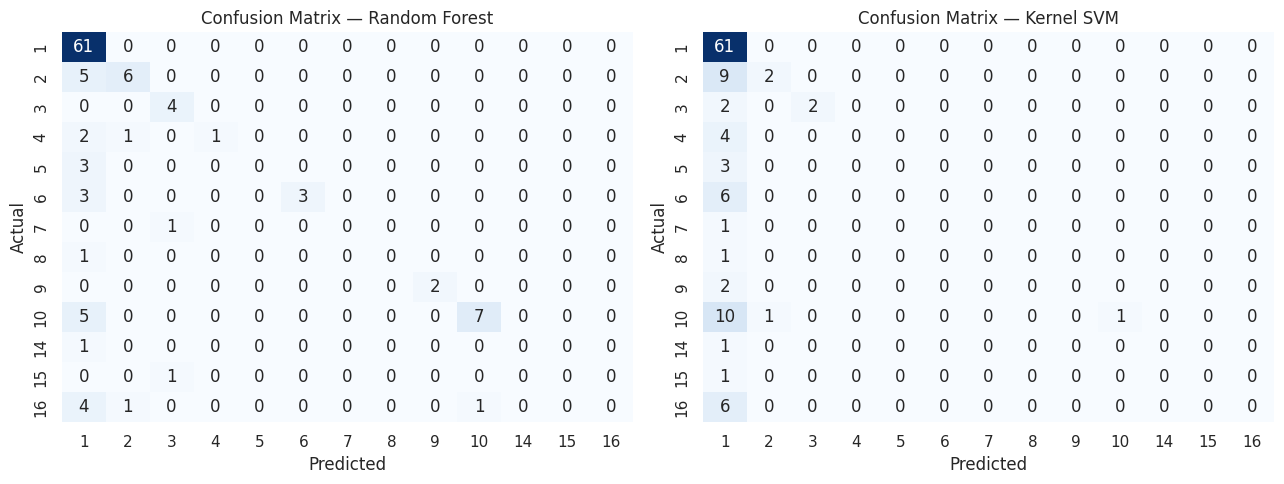

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ['Random Forest', 'Kernel SVM']):
    model = models_before[name]
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()), cbar=False)
    ax.set_title(f'Confusion Matrix — {name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


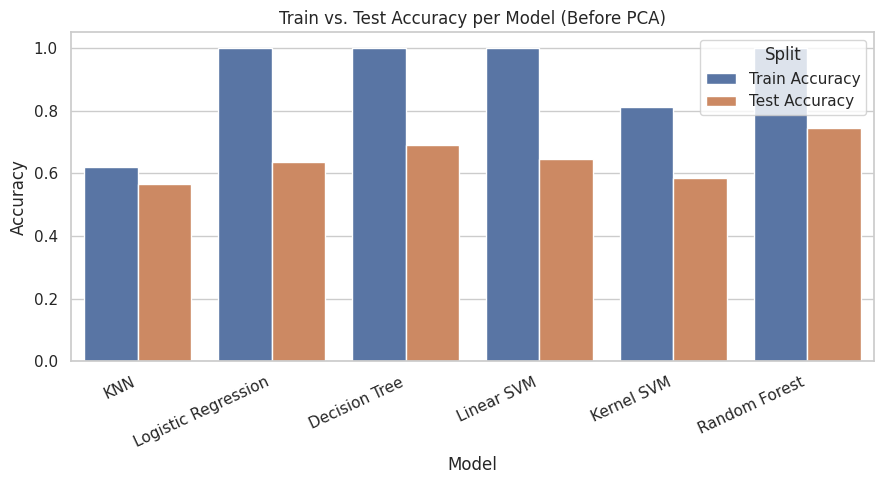

,Model,Train Accuracy,Test Accuracy,Overfit Gap (Train - Test Acc.)
0,KNN,0.619469,0.566372,0.053097
1,Logistic Regression,1.000000,0.637168,0.362832
2,Decision Tree,1.000000,0.690265,0.309735
3,Linear SVM,1.000000,0.646018,0.353982
4,Kernel SVM,0.811209,0.584071,0.227139
5,Random Forest,1.000000,0.743363,0.256637


In [17]:

plot_df = results_before_df.melt(id_vars='Model',
                                  value_vars=['Train Accuracy', 'Test Accuracy'],
                                  var_name='Split', value_name='Accuracy')

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x='Model', y='Accuracy', hue='Split')
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 1.05)
plt.title('Train vs. Test Accuracy per Model (Before PCA)')
plt.tight_layout()
plt.show()

results_before_df['Overfit Gap (Train - Test Acc.)'] = (
    results_before_df['Train Accuracy'] - results_before_df['Test Accuracy']
)
results_before_df[['Model', 'Train Accuracy', 'Test Accuracy', 'Overfit Gap (Train - Test Acc.)']]


Train vs test accuracy before PCA:

- Logistic Regression, Linear SVM and Decision Tree have the biggest gaps (0.36, 0.35 and 0.31). Logistic Regression and Linear SVM score 100% on the training set but only around 64-65% on the test set.
- Random Forest also gets 100% on train (gap 0.26) but it still has the best test accuracy (0.74).
- Kernel SVM has a gap of 0.23.
- KNN has the smallest gap (0.05), but that is because its training accuracy is low as well (0.62). It doesn't fit the training data well in the first place.

So with 261 features and only 339 training rows, most of the models overfit, including the linear ones.

## 6. PCA

There are 261 features but only 339 training samples, so reducing the dimensions might help with overfitting and noise. PCA is fitted on the scaled training data only, and the number of components is chosen so that 95% of the variance is kept.

Number of components needed to explain >= 95% of variance: 92
Original number of features: 261


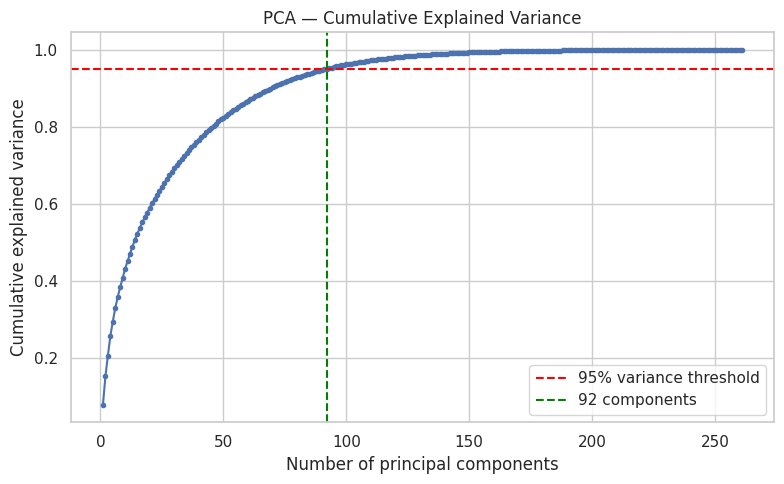

In [18]:

from sklearn.decomposition import PCA

# fit with all components first, just to look at the explained variance curve
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1

print(f"Number of components needed to explain >= 95% of variance: {n_components_95}")
print(f"Original number of features: {X_train_scaled.shape[1]}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='.')
plt.axhline(0.95, color='red', linestyle='--', label='95% variance threshold')
plt.axvline(n_components_95, color='green', linestyle='--',
            label=f'{n_components_95} components')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA — Cumulative Explained Variance')
plt.legend()
plt.tight_layout()
plt.show()


The curve above shows the cumulative explained variance. The smallest number of components that reaches 95% is 92. The final PCA is fitted with that number and used to transform both train and test sets.

In [19]:

pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Dimensionality BEFORE PCA: {X_train_scaled.shape[1]} features")
print(f"Dimensionality AFTER PCA:  {X_train_pca.shape[1]} components")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.1%}")


Dimensionality BEFORE PCA: 261 features
Dimensionality AFTER PCA:  92 components
Variance retained: 95.1%


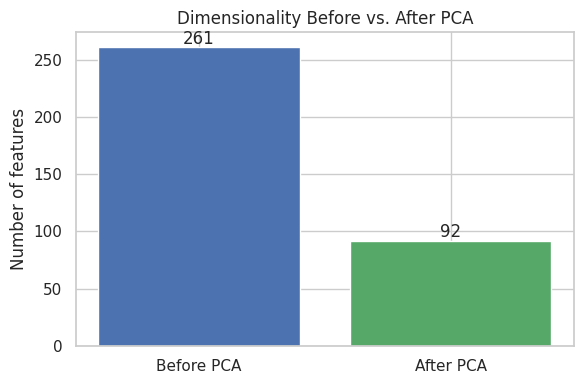

In [20]:

plt.figure(figsize=(6, 4))
plt.bar(['Before PCA', 'After PCA'],
        [X_train_scaled.shape[1], X_train_pca.shape[1]],
        color=['#4C72B0', '#55A868'])
plt.ylabel('Number of features')
plt.title('Dimensionality Before vs. After PCA')
for i, v in enumerate([X_train_scaled.shape[1], X_train_pca.shape[1]]):
    plt.text(i, v + 3, str(v), ha='center')
plt.tight_layout()
plt.show()


## 7. Train the models after PCA

Same models, same helper function, but on the 92 PCA components.

In [21]:

results_after_pca = []
models_after = get_models()

for name, model in models_after.items():
    metrics, _ = evaluate_model(name, model, X_train_pca, y_train, X_test_pca, y_test)
    results_after_pca.append(metrics)

results_after_df = pd.DataFrame(results_after_pca)
results_after_df


===== KNN =====
Train accuracy: 0.634 | Test accuracy: 0.566
Train recall (weighted): 0.634 | Test recall (weighted): 0.566
Test precision (weighted): 0.465

Confusion matrix (test set):
[[60  1  0  0  0  0  0  0  0  0  0  0  0]
 [11  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  0  2  0  0  0  0  0  0  0  0  0  0]
 [ 4  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  1  0  0  0  0]
 [11  0  0  0  0  0  0  0  0  1  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  1  0  0  0  0  0  0  0  0  0  0  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.57      0.98      0.72        61
           2       0.00      0.00      0.00        11
           3       1.00      0.50      0.67         4
           4  

===== Linear SVM =====
Train accuracy: 0.997 | Test accuracy: 0.664
Train recall (weighted): 0.997 | Test recall (weighted): 0.664
Test precision (weighted): 0.654

Confusion matrix (test set):
[[51  3  0  0  0  3  0  0  0  1  0  0  3]
 [ 4  7  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  4  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  3  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  1  0  0  0  0  0  0  0  1]
 [ 1  0  0  0  0  4  0  0  0  0  0  0  1]
 [ 0  0  1  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  2  0  0  0  0]
 [ 6  1  0  0  2  0  0  0  0  3  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  1]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  2  0  0  0  0  0  1  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.74      0.84      0.78        61
           2       0.64      0.64      0.64        11
           3       0.80      1.00      0.89         4
       

===== Random Forest =====
Train accuracy: 1.000 | Test accuracy: 0.584
Train recall (weighted): 1.000 | Test recall (weighted): 0.584
Test precision (weighted): 0.454

Confusion matrix (test set):
[[60  1  0  0  0  0  0  0  0  0  0  0  0]
 [10  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  2  0  0  0  0  0  0  1  0  0  0]
 [ 4  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 6  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 9  0  0  0  0  0  0  0  0  3  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  1  0  0  0  0  0  0  0  0  0  0  0]]

Classification report (test set):
              precision    recall  f1-score   support

           1       0.58      0.98      0.73        61
           2       0.25      0.09      0.13        11
           3       1.00      0.50      0.67         4
    

,Model,Train Accuracy,Test Accuracy,Train Recall (weighted),Test Recall (weighted),Test Precision (weighted)
0,KNN,0.634218,0.566372,0.634218,0.566372,0.464852
1,Logistic Regression,0.979351,0.637168,0.979351,0.637168,0.600776
2,Decision Tree,1.000000,0.389381,1.000000,0.389381,0.393128
3,Linear SVM,0.997050,0.663717,0.997050,0.663717,0.654457
4,Kernel SVM,0.796460,0.601770,0.796460,0.601770,0.514267
5,Random Forest,1.000000,0.584071,1.000000,0.584071,0.453841


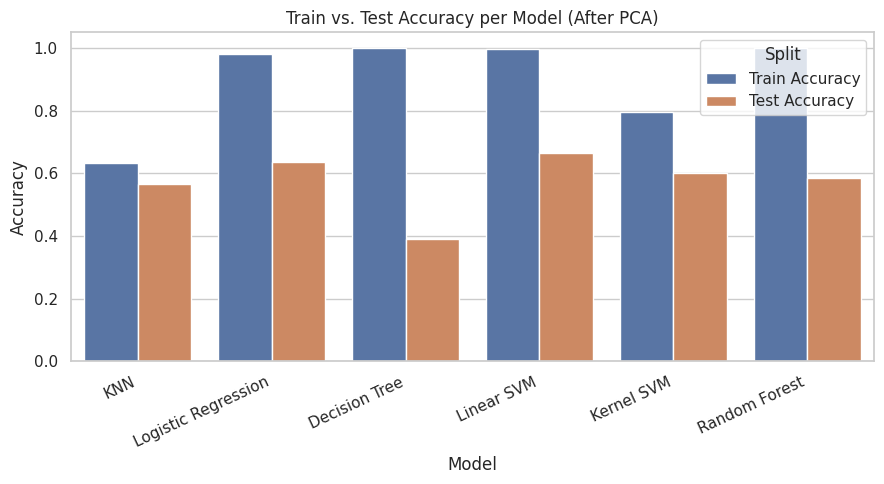

,Model,Train Accuracy,Test Accuracy,Overfit Gap (Train - Test Acc.)
0,KNN,0.634218,0.566372,0.067847
1,Logistic Regression,0.979351,0.637168,0.342183
2,Decision Tree,1.000000,0.389381,0.610619
3,Linear SVM,0.997050,0.663717,0.333333
4,Kernel SVM,0.796460,0.601770,0.194690
5,Random Forest,1.000000,0.584071,0.415929


In [22]:

plot_df_pca = results_after_df.melt(id_vars='Model',
                                     value_vars=['Train Accuracy', 'Test Accuracy'],
                                     var_name='Split', value_name='Accuracy')

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df_pca, x='Model', y='Accuracy', hue='Split')
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 1.05)
plt.title('Train vs. Test Accuracy per Model (After PCA)')
plt.tight_layout()
plt.show()

results_after_df['Overfit Gap (Train - Test Acc.)'] = (
    results_after_df['Train Accuracy'] - results_after_df['Test Accuracy']
)
results_after_df[['Model', 'Train Accuracy', 'Test Accuracy', 'Overfit Gap (Train - Test Acc.)']]


## 8. Before vs after PCA

Test accuracy and test recall for each model before and after PCA, and the change. Weighted recall is mathematically the same as accuracy, which is why those two columns match.

In [23]:

comparison = pd.DataFrame({
    'Model': results_before_df['Model'],
    'Accuracy Before PCA': results_before_df['Test Accuracy'].round(3),
    'Accuracy After PCA': results_after_df['Test Accuracy'].round(3),
    'Recall Before PCA': results_before_df['Test Recall (weighted)'].round(3),
    'Recall After PCA': results_after_df['Test Recall (weighted)'].round(3),
})
comparison['Accuracy Change'] = (comparison['Accuracy After PCA'] - comparison['Accuracy Before PCA']).round(3)
comparison['Recall Change'] = (comparison['Recall After PCA'] - comparison['Recall Before PCA']).round(3)
comparison


,Model,Accuracy Before PCA,Accuracy After PCA,Recall Before PCA,Recall After PCA,Accuracy Change,Recall Change
0,KNN,0.566,0.566,0.566,0.566,0.000,0.000
1,Logistic Regression,0.637,0.637,0.637,0.637,0.000,0.000
2,Decision Tree,0.690,0.389,0.690,0.389,-0.301,-0.301
3,Linear SVM,0.646,0.664,0.646,0.664,0.018,0.018
4,Kernel SVM,0.584,0.602,0.584,0.602,0.018,0.018
5,Random Forest,0.743,0.584,0.743,0.584,-0.159,-0.159


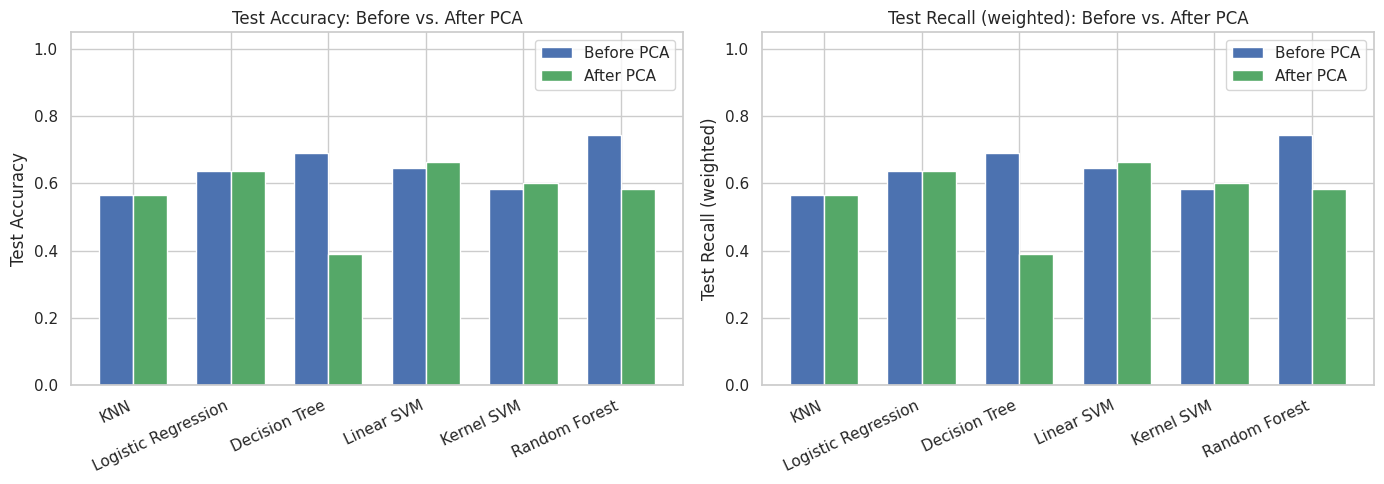

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(comparison))
width = 0.35

axes[0].bar(x - width/2, comparison['Accuracy Before PCA'], width, label='Before PCA', color='#4C72B0')
axes[0].bar(x + width/2, comparison['Accuracy After PCA'], width, label='After PCA', color='#55A868')
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison['Model'], rotation=25, ha='right')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Test Accuracy: Before vs. After PCA')
axes[0].set_ylim(0, 1.05)
axes[0].legend()

axes[1].bar(x - width/2, comparison['Recall Before PCA'], width, label='Before PCA', color='#4C72B0')
axes[1].bar(x + width/2, comparison['Recall After PCA'], width, label='After PCA', color='#55A868')
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison['Model'], rotation=25, ha='right')
axes[1].set_ylabel('Test Recall (weighted)')
axes[1].set_title('Test Recall (weighted): Before vs. After PCA')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()


## 9. Conclusions

**Data.** The dataset is small (452 patients) but has a lot of features. `J_angle` had about 83% missing values and was dropped, a few lightly-missing columns were filled with the median, 17 constant columns were removed, and the features were scaled using the training set only.

**Class imbalance.** 13 classes appear in the data, from 245 normal patients down to classes with 2-5 patients. That is why weighted recall and precision were reported next to accuracy.

**Overfitting before PCA.** Almost every model fit the training set much better than the test set. Logistic Regression, Linear SVM and Decision Tree had the largest gaps (0.31-0.36). KNN had the smallest gap, but it also had the lowest training accuracy.

**Effect of PCA (261 features down to 92 components, 95.1% of the variance kept).**
- Linear SVM and Kernel SVM improved a little (0.646 to 0.664 and 0.584 to 0.602), and Logistic Regression and KNN stayed the same.
- Decision Tree got much worse (0.690 to 0.389) and Random Forest dropped too (0.743 to 0.584). Their train/test gaps also grew (0.31 to 0.61 and 0.26 to 0.42). This is probably because PCA mixes the original features into combinations, and tree models work better with the original single features.
- The gap got slightly smaller for Logistic Regression, Linear SVM and Kernel SVM, and slightly bigger for KNN.

**Overall.** PCA did not help in general here. It helped a bit for the SVMs and hurt the tree-based models. The best result overall is Random Forest without PCA (0.743 test accuracy); the best after PCA is Linear SVM (0.664).

**Limitations.** The test set only has 113 patients, so a change of 0.018 is about 2 patients and could easily be noise. Several classes have too few samples for reliable per-class results. Cross-validation over several splits would give a more trustworthy comparison.